In [11]:
import sys
sys.path.append(r"C:\Users\papan\Desktop\Coffeomics")
import pandas as pd
from data_characterization import to_bar_graph_counts_per_sample

type = 'Transcriptomics'
file_path = r"C:\Users\papan\Desktop\Coffeomics\Coffeeomics.xlsx"
trans_raw_data = pd.read_excel(file_path, sheet_name="Trans_Counts", index_col=0, header=4)

In [14]:
import pandas as pd
sample_metadata = pd.read_excel(r'C:\Users\papan\Desktop\Coffeomics\Coffeeomics.xlsx', sheet_name='Samples', index_col=0)
filtered_df = sample_metadata.loc[sample_metadata[type].notna(), ["Species", "Temperature", "CO2", "Water Stress"]]
transposed = filtered_df.T

arabica_ids = transposed.loc[:, transposed.loc["Species"] == "C. arabica"].columns
canephora_ids = transposed.loc[:, transposed.loc["Species"] == "C. canephora"].columns

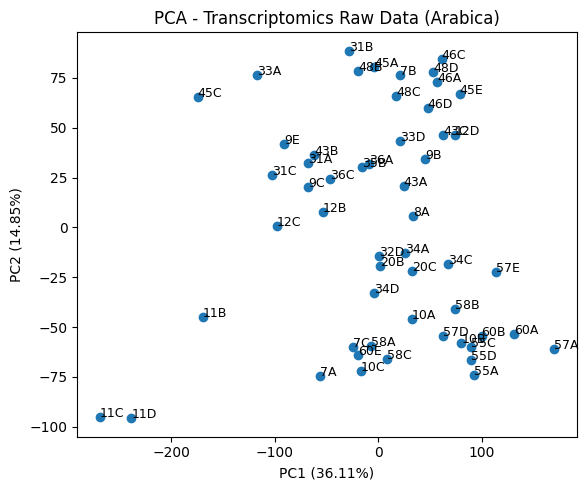

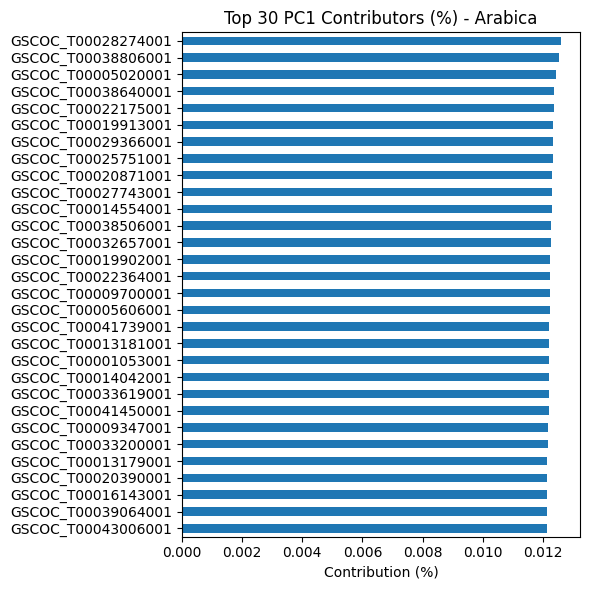

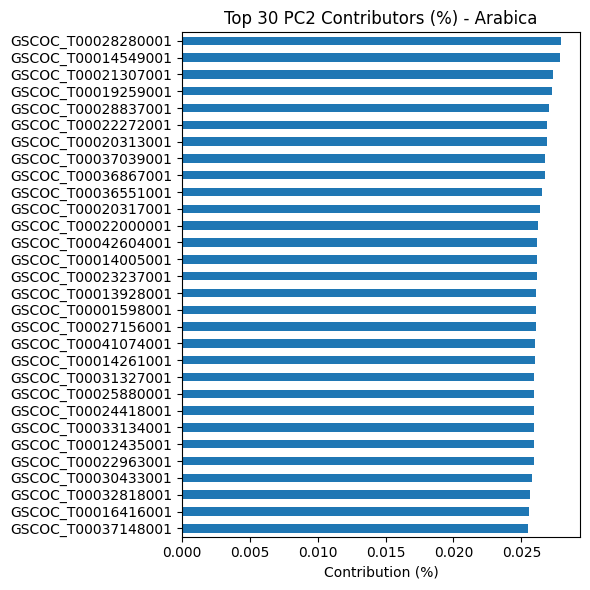

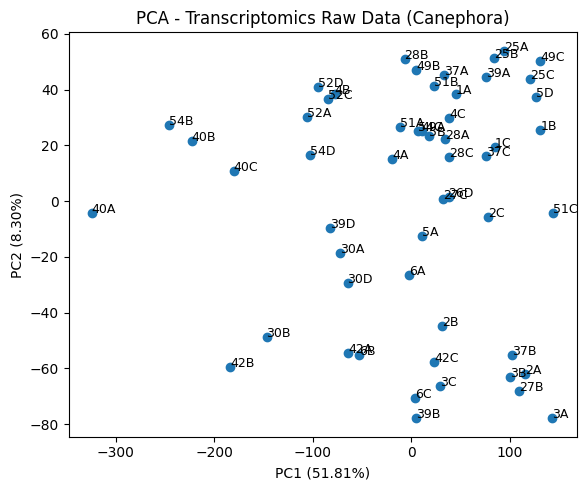

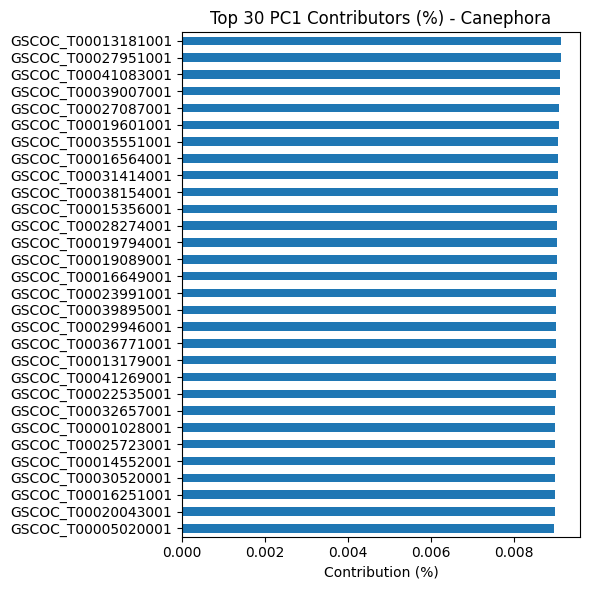

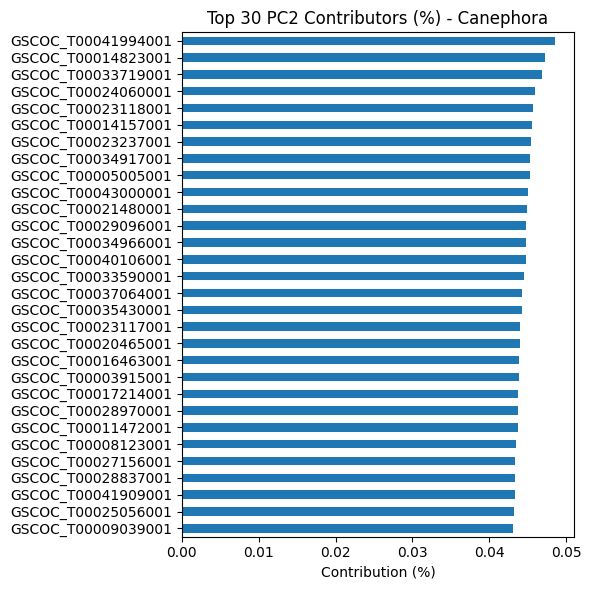

In [15]:
from pca import run_pca_analysis
run_pca_analysis(trans_raw_data, arabica_ids=arabica_ids, canephora_ids=canephora_ids, name="Transcriptomics Raw Data", top=30, log_transform=True)

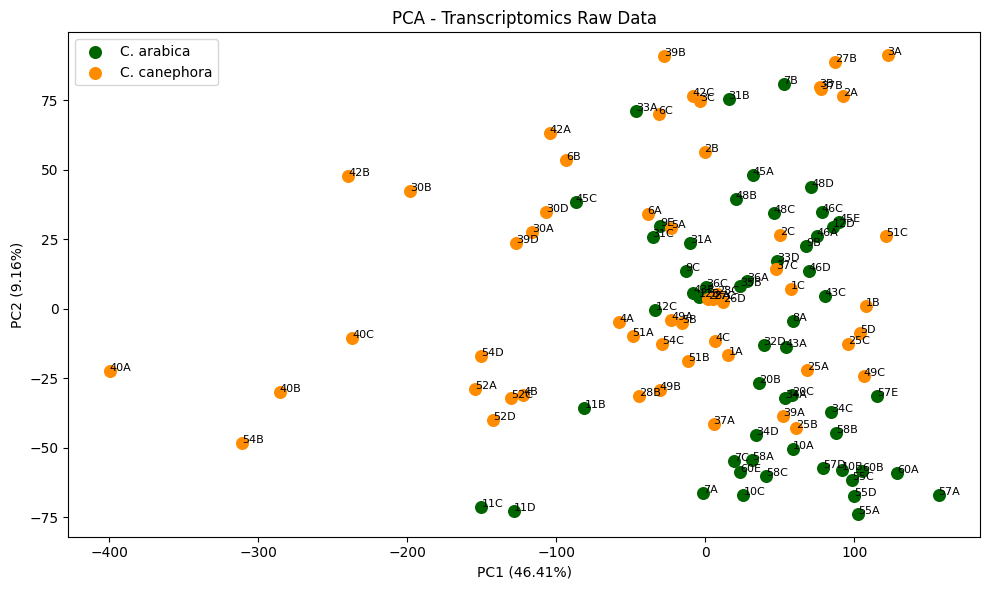

(            PC1        PC2       Species
 7A    -1.374480 -66.253753    C. arabica
 7B    52.468248  80.796237    C. arabica
 7C    19.376396 -54.627871    C. arabica
 20B   36.248833 -26.526065    C. arabica
 20C   57.975569 -30.824740    C. arabica
 ..          ...        ...           ...
 52C -130.554153 -32.127148  C. canephora
 52D -142.681549 -40.079461  C. canephora
 54B -311.210547 -48.233634  C. canephora
 54C  -29.262014 -12.702989  C. canephora
 54D -150.635016 -17.090996  C. canephora
 
 [108 rows x 3 columns],
                          PC1       PC2
 GSCOC_T00012439001  0.004525 -0.002277
 GSCOC_T00012438001  0.009067  0.000733
 GSCOC_T00012437001  0.008901  0.005978
 GSCOC_T00012436001  0.003173  0.010890
 GSCOC_T00012435001  0.002562 -0.015684
 ...                      ...       ...
 GSCOC_T00040990001  0.000958 -0.001311
 GSCOC_T00040989001  0.009597  0.001511
 GSCOC_T00040988001  0.009467  0.002186
 GSCOC_T00040987001  0.002634  0.001963
 GSCOC_T00040986001  0.009626

In [16]:
from pca import run_pca_analysis_colured
run_pca_analysis_colured(trans_raw_data, species_series = transposed.loc["Species"], name="Transcriptomics Raw Data", top=30, log_transform=True)

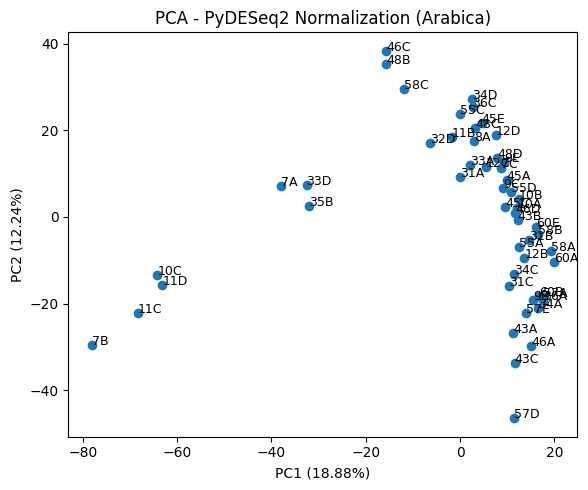

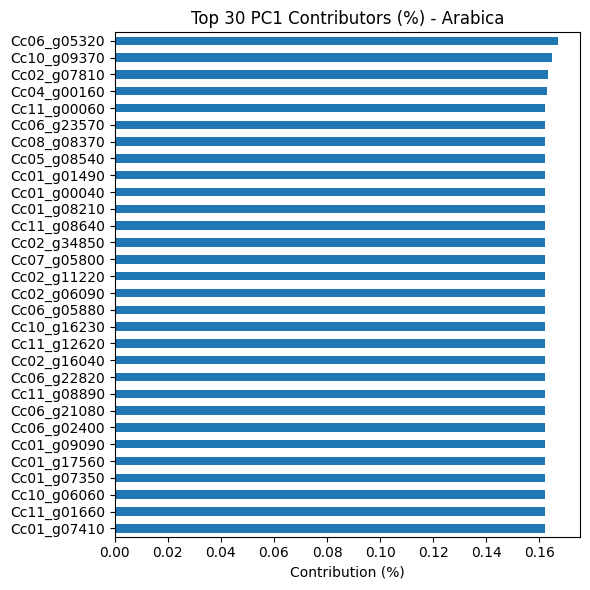

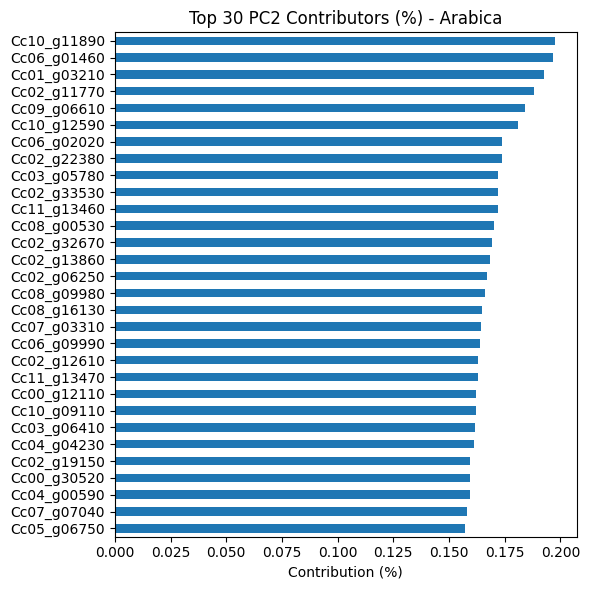

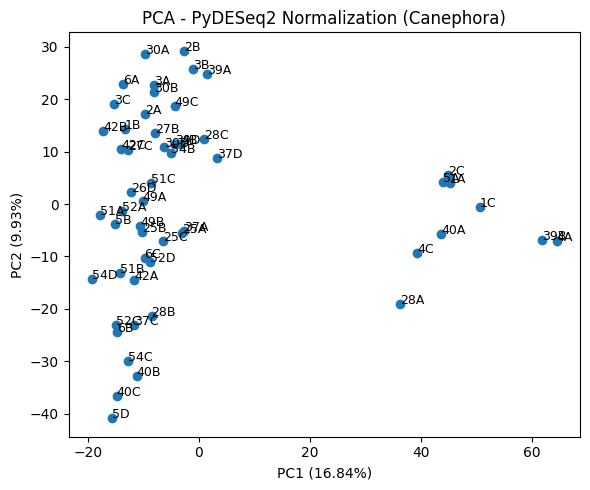

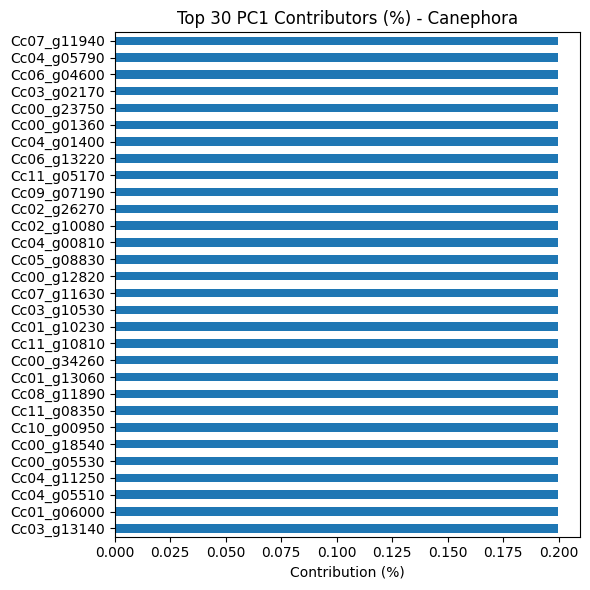

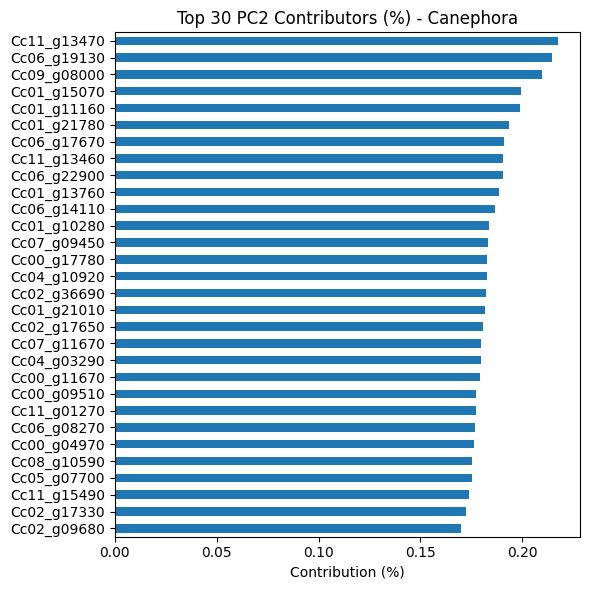

In [8]:
pydeseq2_norm = pd.read_csv(
    r"C:\Users\papan\Desktop\Coffeomics\proteomics\prot_conts_pyseq2_normalized.csv",
    index_col=0
)

run_pca_analysis(pydeseq2_norm.T, arabica_ids=arabica_ids, canephora_ids=canephora_ids, name="PyDESeq2 Normalization", top=30, log_transform=True)

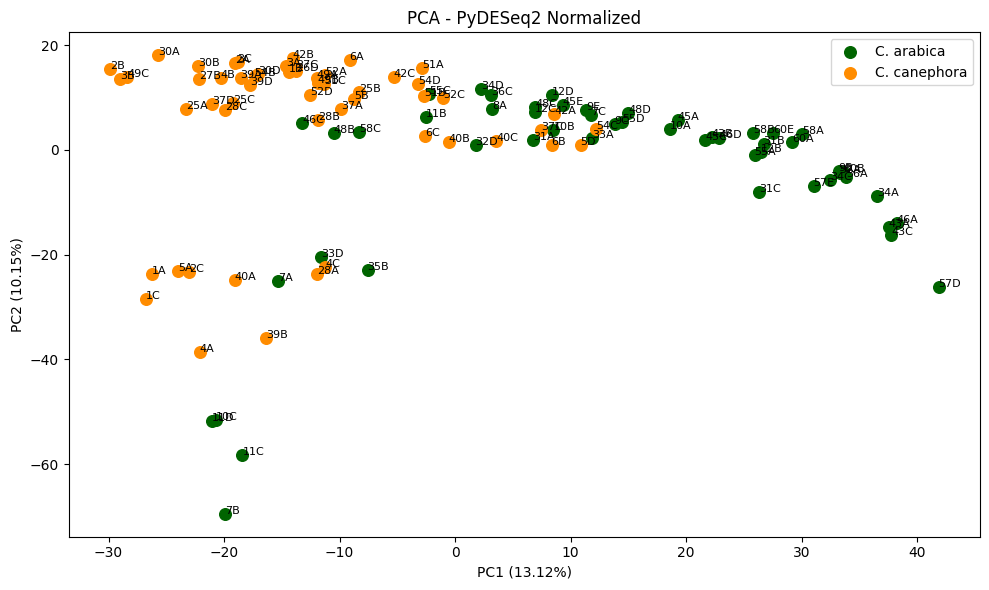

(              PC1        PC2       Species
 sample                                    
 7A     -15.350076 -25.106416    C. arabica
 7B     -19.880667 -69.507139    C. arabica
 7C      11.751924   6.657875    C. arabica
 8A       3.180627   7.736598    C. arabica
 9B      33.185934  -4.004424    C. arabica
 ...           ...        ...           ...
 52C     -1.053548   9.954343  C. canephora
 52D    -12.579895  10.407846  C. canephora
 54B    -17.359063  14.116034  C. canephora
 54C     12.171020   3.945656  C. canephora
 54D     -3.175533  12.513733  C. canephora
 
 [106 rows x 3 columns],
                   PC1       PC2
 Cc11_g02460 -0.013091 -0.035746
 Cc11_g12000 -0.013091 -0.035746
 Cc03_g15640 -0.014114 -0.027430
 Cc01_g07410 -0.009421 -0.026408
 Cc03_g13140 -0.001987 -0.033878
 ...               ...       ...
 Cc01_g10720  0.008372  0.029190
 Cc02_g07500  0.035059  0.029965
 Cc00_g11330 -0.030020  0.020625
 Cc07_g05350 -0.004866  0.019993
 Cc06_g12080 -0.023138  0.008734
 
 [2

In [9]:
run_pca_analysis_colured(pydeseq2_norm.T, species_series = transposed.loc["Species"], name="PyDESeq2 Normalized", top=30, log_transform=True)

In [ ]:
import pandas as pd
sample_metadata = pd.read_excel('Coffeeomics.xlsx', sheet_name='Samples', index_col=0)
filtered_df = sample_metadata.loc[sample_metadata["Proteomics"].notna(), ["Species", "Temperature", "CO2", "Water Stress"]]
outliers_1 = filtered_df.loc[['7A', '33D', '35B']]
outliers_2 = filtered_df.loc[['4A', '39B']]
outliers_3 = filtered_df.loc[['10C', '11C', '11D']]
outliers_4 = filtered_df.loc[[ '1A', '1C', '2C', '4C', '5A', '28A', '40A']]
display(outliers_4)

In [ ]:
import pandas as pd
sample_metadata = pd.read_excel('Coffeeomics.xlsx', sheet_name='Samples', index_col=0)
filtered_df = sample_metadata.loc[sample_metadata["Proteomics"].notna(), ["Species", "Temperature", "CO2", "Water Stress"]]
outliers_1 = filtered_df.loc[['7B']]
outliers_2 = filtered_df.loc[['10C', '11C', '11D']]
outliers_3 = filtered_df.loc[['7A', '33D', '35B', '57D', '1A', '1C', '2C', '4A', '4C', '5A', '28A', '39B', '40A']]
display(outliers_3)